In [1]:
import copy
import datetime as dt
from datetime import datetime
import importlib  # needed so that we can reload packages
import logging
import os
import pathlib
import sys
import time
import warnings
from typing import Union, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# --- Make notebooks/ importable from any sector subfolder ---
import os, sys, pathlib
_NB_PARENT = pathlib.Path(os.getcwd()).parent  # notebooks/<sector>/ -> notebooks/
if str(_NB_PARENT) not in sys.path:
    sys.path.insert(0, str(_NB_PARENT))

from utils.logger_utils import setup_clean_logger, mute_external_loggers

# SISEPUEDE imports
from sisepuede.manager.sisepuede_examples import SISEPUEDEExamples
from sisepuede.manager.sisepuede_file_structure import SISEPUEDEFileStructure
import sisepuede.core.support_classes as sc
import sisepuede.utilities._plotting as spu
import sisepuede.utilities._toolbox as sf
import sisepuede.core.attribute_table as att
import sisepuede.manager.sisepuede_examples as sxl
import sisepuede.manager.sisepuede_file_structure as sfs
import sisepuede.manager.sisepuede_models as sm
import sisepuede.visualization.plots as svp



# --- Runtime configuration ---
warnings.filterwarnings("ignore")

# Set up a clean logger for your notebook
logger = setup_clean_logger("notebook", logging.INFO)
logger.info("Notebook started successfully.")

# Mute logs from sisepuede to avoid duplication
mute_external_loggers(["sisepuede"])
# run this on the terminal /opt/anaconda3/envs/ssp_libya_env_2/bin/python -m pip install "setuptools>=60,<70"

2026-11-09 16:42:10,128 - INFO - Notebook started successfully.


In [2]:
%load_ext autoreload
%autoreload 2

### Initial Set up

Make sure to edit the config yaml under ssp_modeling/config_files/config.yaml

You can also create a new config yaml



In [3]:
# Set up dir paths

CURR_DIR_PATH = pathlib.Path(os.getcwd())
NOTEBOOKS_DIR_PATH = CURR_DIR_PATH
SSP_MODELING_DIR_PATH = NOTEBOOKS_DIR_PATH.parent
PROJECT_DIR_PATH = SSP_MODELING_DIR_PATH.parent
DATA_DIR_PATH = SSP_MODELING_DIR_PATH.joinpath("input_data")
RUN_OUTPUT_DIR_PATH = SSP_MODELING_DIR_PATH.joinpath("ssp_run_output")
SCENARIO_MAPPING_DIR_PATH = SSP_MODELING_DIR_PATH.joinpath("scenario_mapping")
CONFIG_DIR_PATH = NOTEBOOKS_DIR_PATH.joinpath("config_files")
TRANSFORMATIONS_DIR_PATH = SSP_MODELING_DIR_PATH.joinpath("transformations")
MISC_DIR_PATH = SSP_MODELING_DIR_PATH.joinpath("misc")
STRATEGIES_DEFINITIONS_FILE_PATH = TRANSFORMATIONS_DIR_PATH.joinpath("strategy_definitions.csv")
STRATEGY_MAPPING_FILE_PATH = MISC_DIR_PATH.joinpath("strategy_mapping.yaml")

In [4]:
from ssp_transformations_handler.GeneralUtils import GeneralUtils
from ssp_transformations_handler.TransformationUtils import TransformationYamlProcessor, StrategyCSVHandler

# Initialize general utilities
g_utils = GeneralUtils()

In [5]:
# Load config file, double check your parameters are correct

YAML_FILE_PATH = os.path.join(CONFIG_DIR_PATH, "config.yaml")
config_params = g_utils.read_yaml(YAML_FILE_PATH)

country_name = config_params['country_name']
ssp_input_file_name = config_params['ssp_input_file_name']
ssp_transformation_cw = config_params['ssp_transformation_cw']
energy_model_flag = config_params['energy_model_flag']
set_lndu_reallocation_factor_to_zero_flag = config_params['set_lndu_reallocation_factor_to_zero']
sim_end_year = config_params.get('sim_end_year', 2050)  # Default to 2050 if not specified

# Print config parameters
logger.info(f"Country name: {country_name}")
logger.info(f"SSP input file name: {ssp_input_file_name}")
logger.info(f"SSP transformation CW: {ssp_transformation_cw}")
logger.info(f"Energy model flag: {energy_model_flag}")
logger.info(f"Set lndu reallocation factor to zero flag: {set_lndu_reallocation_factor_to_zero_flag}")
logger.info(f"Simulation end year: {sim_end_year}")

2026-11-09 16:42:10,217 - INFO - Country name: indonesia
2026-11-09 16:42:10,217 - INFO - SSP input file name: sspv2_input_data_idn_iea_calibrated_2020_20261109.csv
2026-11-09 16:42:10,218 - INFO - SSP transformation CW: ssp_indonesia_transformation_cw.xlsx
2026-11-09 16:42:10,218 - INFO - Energy model flag: True
2026-11-09 16:42:10,218 - INFO - Set lndu reallocation factor to zero flag: True
2026-11-09 16:42:10,218 - INFO - Simulation end year: 2050


In [6]:
def get_file_structure(
    y0: int = 2015,
    y1: int = sim_end_year,
) -> Tuple[sfs.SISEPUEDEFileStructure, att.AttributeTable]:
    """Get the SISEPUEDE File Structure and update the attribute table
        with new years.
    """
    # setup some SISEPUEDE variables and update time period
    file_struct = sfs.SISEPUEDEFileStructure(
        initialize_directories = False,
    )
 
    # get some keys
    key_time_period = file_struct.model_attributes.dim_time_period
    key_year = file_struct.model_attributes.field_dim_year
 
 
    ##  BUILD THE ATTRIBUTE AND UPDATE
 
    # setup the new attribute table
    years = np.arange(y0, y1 + 1, ).astype(int)
    attribute_time_period = att.AttributeTable(
        pd.DataFrame(
            {
                key_time_period: range(len(years)),
                key_year: years,
            }
        ),
        key_time_period,
    )
 
    # finally, update the ModelAttributes inside the file structure
    (
        file_struct
        .model_attributes
        .update_dimensional_attribute_table(
            attribute_time_period,
        )
    )
 
    # return the tuple
    out = (file_struct, attribute_time_period, )
 
    return out


In [7]:
# Set up SSP objects
INPUT_FILE_PATH = DATA_DIR_PATH.joinpath(ssp_input_file_name)

# model attributes and associated support classes
_EXAMPLES = sxl.SISEPUEDEExamples()
_FILE_STRUCTURE, _ATTRIBUTE_TABLE_TIME_PERIOD = get_file_structure(y1=sim_end_year)
matt = _FILE_STRUCTURE.model_attributes
regions = sc.Regions(matt, )
time_periods = sc.TimePeriods(matt, )
 

In [8]:
# setup models in case we need them
models = sm.SISEPUEDEModels(
    matt,
    allow_electricity_run = True,
    fp_julia = _FILE_STRUCTURE.dir_jl,
    fp_nemomod_reference_files = _FILE_STRUCTURE.dir_ref_nemo,
    initialize_julia = False, 
)

### Making sure our input file has the correct format and correct columns
We use an example df with the complete fields and correct format to make sure our file is in the right shape

In [9]:
##  BUILD BASE INPUTS
df_inputs_raw = pd.read_csv(INPUT_FILE_PATH)

# pull example data to fill in gaps
df_example_input = _EXAMPLES("input_data_frame")

In [10]:
# Double checking that our df is in the correct shape (Empty sets should be printed to make sure everything is Ok!)
g_utils.compare_dfs(df_example_input, df_inputs_raw)

Columns in df_example but not in df_input: {'nemomod_entc_input_activity_ratio_fuel_production_fp_hydrogen_gasification_biomass', 'region', 'nemomod_entc_grid_power_constraint_mmm_usd'}
Columns in df_input but not in df_example: {'iso_alpha_3', 'year'}


In [11]:
all_fields = matt.all_variable_fields_input
df_fiels = df_inputs_raw.columns.tolist()
missing_fields = list(set(all_fields) - set(df_fiels))
print("Missing fields in the input data frame:")
print(missing_fields)

Missing fields in the input data frame:
[]


In [12]:
# Ensure if time_period field exist
if 'time_period' not in df_inputs_raw.columns:
    logger.info("Adding 'time_period' column to df_inputs_raw")
    df_inputs_raw = df_inputs_raw.rename(columns={'period':'time_period'})
else:
    logger.info("'time_period' column already exists in df_inputs_raw")

2026-11-09 16:42:11,350 - INFO - 'time_period' column already exists in df_inputs_raw


In [13]:
# Fixes differences and makes sure that our df is in the correct format.
# Note: Edit this if you need more changes in your df

df_inputs_raw_complete = g_utils.add_missing_cols(df_example_input, df_inputs_raw.copy())
df_inputs_raw_complete.head()

,year,time_period,avgload_trns_freight_tonne_per_vehicle_aviation,avgload_trns_freight_tonne_per_vehicle_rail_freight,avgload_trns_freight_tonne_per_vehicle_road_heavy_freight,avgload_trns_freight_tonne_per_vehicle_water_borne,avgmass_lvst_animal_buffalo_kg,avgmass_lvst_animal_cattle_dairy_kg,avgmass_lvst_animal_cattle_nondairy_kg,avgmass_lvst_animal_chickens_kg,...,nemomod_entc_biomass_msp_replacement_tag_pp_solar,nemomod_entc_biomass_msp_replacement_tag_pp_waste_incineration,nemomod_entc_biomass_msp_replacement_tag_pp_wind,biomass_frst_ledger_frac_yf_priority_removals,biomass_frst_ledger_frac_dom_deadwood,biomass_frst_ledger_frac_deadwood_removed,biomass_frst_ledger_removals_behavioral_adjustment_factor,region,nemomod_entc_input_activity_ratio_fuel_production_fp_hydrogen_gasification_biomass,nemomod_entc_grid_power_constraint_mmm_usd
0,2015,0,70,2923,31.751466,6468,315,508,303,1.1,...,1,1,1,0,0.615,0.25,0,costa_rica,0.0,-999
1,2016,1,70,2923,31.751466,6468,315,508,303,1.1,...,1,1,1,0,0.615,0.25,0,costa_rica,0.0,-999
2,2017,2,70,2923,31.751466,6468,315,508,303,1.1,...,1,1,1,0,0.615,0.25,0,costa_rica,0.0,-999
3,2018,3,70,2923,31.751466,6468,315,508,303,1.1,...,1,1,1,0,0.615,0.25,0,costa_rica,0.0,-999
4,2019,4,70,2923,31.751466,6468,315,508,303,1.1,...,1,1,1,0,0.615,0.25,0,costa_rica,0.0,-999


In [14]:
# Double checking that our df is in the correct shape (Empty sets should be printed to make sure everything is Ok!)
g_utils.compare_dfs(df_example_input, df_inputs_raw_complete)

Columns in df_example but not in df_input: set()
Columns in df_input but not in df_example: {'iso_alpha_3', 'year'}


In [15]:
df_inputs_raw_complete["region"].head()

0    costa_rica
1    costa_rica
2    costa_rica
3    costa_rica
4    costa_rica
Name: region, dtype: str

In [16]:
# Set region to country name
df_inputs_raw_complete['region'] = country_name
df_inputs_raw_complete['region'].head()

0    indonesia
1    indonesia
2    indonesia
3    indonesia
4    indonesia
Name: region, dtype: str

In [17]:
# filter to match sim_end_year
print(f"min and max years in raw inputs before filtering: {df_inputs_raw_complete['year'].min()} to {df_inputs_raw_complete['year'].max()}")
df_inputs_raw_complete = df_inputs_raw_complete[df_inputs_raw_complete['year'] <= sim_end_year]
print(f"min and max years in raw inputs after filtering: {df_inputs_raw_complete['year'].min()} to {df_inputs_raw_complete['year'].max()}")

min and max years in raw inputs before filtering: 2015 to 2050
min and max years in raw inputs after filtering: 2015 to 2050


#  Let's try building transformations using this


In [18]:
import sisepuede.transformers as trf
# sisepuede 2.0 renamed Transformers -> TransformerKernels (keeps working on 1.4 too)
_Transformers = trf.TransformerKernels if hasattr(trf, "TransformerKernels") else trf.transformers.Transformers
transformers = _Transformers(
    {},
    attr_time_period = _ATTRIBUTE_TABLE_TIME_PERIOD,
    df_input = df_inputs_raw_complete, # here you change the input table
)

##  Instantiate some transformations. Make sure to run this cell to create the transformations folder for the first time or if you wish to overwrite

In [19]:
# set an ouput path and instantiate
if not TRANSFORMATIONS_DIR_PATH.exists():
    trf.instantiate_default_strategy_directory(
        transformers,
        TRANSFORMATIONS_DIR_PATH,
    )
else:
    logger.info(f"Directory {TRANSFORMATIONS_DIR_PATH} already exists. Skipping instantiation.")


2026-11-09 16:42:12,140 - INFO - Directory /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/transformations already exists. Skipping instantiation.


##  --HERE, CUSTOMIZE YOUR TRANSFORMATIONS AND STRATEGIES--

### Customizing transformations and strategies files using TransformationUtils.py classes

In [20]:
# Generate new transformation files based on the excel mapping file. 
# Make sure to have the most updated format for the excel file, check the one used in this notebook for reference.

if ssp_transformation_cw is None:
    logger.warning("ssp_transformation_cw is not defined. Please check your config file.")
else:
    logger.info(f"Using transformation file: {ssp_transformation_cw}")
    cw_file_path = os.path.join(SCENARIO_MAPPING_DIR_PATH, ssp_transformation_cw)
    logger.info(f"Transformation file path: {cw_file_path}")
    excel_yaml_handler = TransformationYamlProcessor(scenario_mapping_excel_path=cw_file_path, yaml_dir_path=TRANSFORMATIONS_DIR_PATH)

2026-11-09 16:42:12,151 - INFO - Using transformation file: ssp_indonesia_transformation_cw.xlsx
2026-11-09 16:42:12,151 - INFO - Transformation file path: /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/scenario_mapping/ssp_indonesia_transformation_cw.xlsx


In [21]:
# This creates transformation yaml files for each strategy in the excel file
if ssp_transformation_cw is not None:
    logger.info("Processing YAML files...")
    excel_yaml_handler.process_yaml_files()
else:
    logger.warning("ssp_transformation_cw is not defined. Please check your config file.")

2026-11-09 16:42:12,236 - INFO - Processing YAML files...


[transformation_agrc_dec_exports.yaml | TX:AGRC:DEC_EXPORTS] Decrease Exports (AGRC) | Start: 10
Strategy: strategy_LEDS, Scalar value: 1.0
Original YAML file transformation_agrc_inc_conservation_agriculture.yaml not found in directory /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/transformations.
[transformation_ccsq_inc_capture.yaml | TX:CCSQ:INC_CAPTURE] Increase direct air capture (CCSQ) | Start: 10
Strategy: strategy_LEDS, Scalar value: 0.3
[transformation_entc_dec_losses.yaml | TX:ENTC:DEC_LOSSES] Reduce transmission losses (ENTC) | Start: 10
Strategy: strategy_bau, Scalar value: 1.0
[transformation_entc_dec_losses.yaml | TX:ENTC:DEC_LOSSES] Reduce transmission losses (ENTC) | Start: 10
Strategy: strategy_LEDS, Scalar value: 1.5
[transformation_entc_target_clean_hydrogen.yaml | TX:ENTC:TARGET_CLEAN_HYDROGEN] Clean hydrogen (ENTC) | Start: 10
Strategy: strategy_bau, Scalar value: 0.25
[transformation_entc_target_clean_hydrogen.yaml | TX:ENTC:TARGET_CLEAN_HYDROGEN] Clean hydr

In [22]:
# Load the transformations per strategy dictionary so we can pass it to the strategy handler
# You can also check here if the transformations in each strategy are correct

if ssp_transformation_cw is not None:
    logger.info("Loading transformations per strategy dictionary...")
    transformation_per_strategy_dict = excel_yaml_handler.get_transformations_per_strategy_dict()
    transformation_per_strategy_dict
    logger.info(f"Loaded transformations for strategies: {transformation_per_strategy_dict.keys()}")
else:
    logger.warning("No transformation handler available. Please check your config file.")

2026-11-09 16:42:12,276 - INFO - Loading transformations per strategy dictionary...
2026-11-09 16:42:12,278 - INFO - Loaded transformations for strategies: dict_keys(['strategy_bau', 'strategy_LEDS'])


### Creating new strategies
- You can create new strategies from scratch.
- You can also update existing ones.

In [23]:
# Creating new strategies by updating the strategy_definitions file.

if ssp_transformation_cw is not None:
    # You can edit this to add yours, as many as you want.
    csv_handler = StrategyCSVHandler(csv_file_path=STRATEGIES_DEFINITIONS_FILE_PATH, 
                                     yaml_dir_path=TRANSFORMATIONS_DIR_PATH, 
                                     yaml_mapping_file=STRATEGY_MAPPING_FILE_PATH, 
                                     transformation_per_strategy_dict=transformation_per_strategy_dict)
    
    csv_handler.add_strategy(strategy_group='PFLO', description='bau', yaml_file_suffix='bau')
    csv_handler.add_strategy(strategy_group='PFLO', description='LEDS', yaml_file_suffix='LEDS')

else:
    logger.warning("No transformation handler available. Please check your config file.")


INFO: Strategy code PFLO:BAU already exists in the strategy definitions. Strategy will be updated...
Updated row with strategy_code PFLO:BAU
INFO: Strategy code PFLO:LEDS already exists in the strategy definitions. Strategy will be updated...
Updated row with strategy_code PFLO:LEDS


In [24]:
# then, you can load this back in after modifying (play around with it)
# sisepuede 2.0: Transformations builds its own kernels from attr_time_period + df_input
transformations = trf.Transformations(
    TRANSFORMATIONS_DIR_PATH,
    attr_time_period = _ATTRIBUTE_TABLE_TIME_PERIOD,
    df_input = df_inputs_raw_complete,
)
transformers = getattr(transformations, "transformers", None) or transformations.transformer_kernels
tab = transformations.attribute_transformation.table

In [25]:
for nm in transformations.all_transformation_codes:
    transformation = transformations.get_transformation(nm)
    try:
        df = transformation()
    except Exception as e:
        logger.error(f"Error processing transformation {transformation.code}: {e}")

2026-11-09 16:42:13,168 - ERROR - Error processing transformation TX:FRST:INCREASE_SEQUESTRATION: 'AFOLU' object has no attribute 'modvar_frst_biomass_growth_rate_co2'
2026-11-09 16:42:13,168 - ERROR - Error processing transformation TX:FRST:INCREASE_SEQUESTRATION_STRATEGY_LEDS: 'AFOLU' object has no attribute 'modvar_frst_biomass_growth_rate_co2'
2026-11-09 16:42:13,491 - ERROR - Error processing transformation TX:LNDU:INC_SILVOPASTURE: 'AFOLU' object has no attribute 'modvar_frst_biomass_growth_rate_co2'
2026-11-09 16:42:13,491 - ERROR - Error processing transformation TX:LNDU:INC_SILVOPASTURE_STRATEGY_LEDS: 'AFOLU' object has no attribute 'modvar_frst_biomass_growth_rate_co2'
2026-11-09 16:42:13,491 - ERROR - Error processing transformation TX:LNDU:INC_SILVOPASTURE_STRATEGY_NDC: 'AFOLU' object has no attribute 'modvar_frst_biomass_growth_rate_co2'
2026-11-09 16:42:13,535 - ERROR - Error processing transformation TX:SCOE:INC_EFFICIENCY_APPLIANCE: transformation_general() got an unexp

In [26]:
#  build the strategies -- will export to path
t0 = time.time()
strategies = trf.Strategies(
    transformations,
    export_path = "transformations",
    prebuild = True,
)

t_elapse = sf.get_time_elapsed(t0)
print(f"Strategies defined at {strategies.transformations.dir_init} initialized in {t_elapse} seconds")

Strategies defined at /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/transformations initialized in 1.23 seconds


In [27]:
strategies.attribute_table

,strategy_id,strategy_code,strategy,description,transformation_specification,baseline_strategy_id
0,0,BASE,Strategy TX:BASE,NaN,TX:BASE,1
1,1000,AGRC:DEC_CH4_RICE,Singleton - Default Value - AGRC: Improve rice...,NaN,TX:AGRC:DEC_CH4_RICE,0
2,1001,AGRC:DEC_EXPORTS,Singleton - Default Value - AGRC: Decrease Exp...,NaN,TX:AGRC:DEC_EXPORTS,0
3,1002,AGRC:DEC_LOSSES_SUPPLY_CHAIN,Singleton - Default Value - AGRC: Reduce suppl...,NaN,TX:AGRC:DEC_LOSSES_SUPPLY_CHAIN,0
4,1004,AGRC:INC_PRODUCTIVITY,Singleton - Default Value - AGRC: Improve crop...,NaN,TX:AGRC:INC_PRODUCTIVITY,0
...,...,...,...,...,...,...
68,6000,PFLO:INC_HEALTHIER_DIETS,Singleton - Default Value - PFLO: Change diets,NaN,TX:PFLO:INC_HEALTHIER_DIETS,0
69,6001,PFLO:INC_IND_CCS,Singleton - Default Value - PFLO: Industrial c...,NaN,TX:PFLO:INC_IND_CCS,0
70,6002,PFLO:ALL,All Actions,All actions (unique by transformer),TX:AGRC:DEC_CH4_RICE|TX:AGRC:DEC_EXPORTS|TX:AG...,0
71,6003,PFLO:BAU,bau,bau,TX:ENTC:TARGET_CLEAN_HYDROGEN_STRATEGY_BAU|TX:...,0


In [28]:
strategies_to_run = [0, 6002]
print(f"Strategies to run: {strategies_to_run}")

Strategies to run: [0, 6002]


In [29]:
strategies.get_strategy(6002)


##  Build our templates
- let's use the default variable groupings for LHS

In [30]:
# Building excel templates, make sure to include the strategies ids in the strategies attribute as well as the baseline (0)
df_vargroups = _EXAMPLES("variable_trajectory_group_specification")

strategies.build_strategies_to_templates(
    # df_trajgroup = df_vargroups,
    # include_simplex_group_as_trajgroup = True,
    strategies = strategies_to_run,
)

6002 running


0

# Finally, load SISEPUEDE and run it

In [31]:
country_name

'indonesia'

In [32]:
import sisepuede as si
# timestamp_str = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
ssp = si.SISEPUEDE(
    "calibrated",
    db_type = "csv",
    # id_str = f"sisepuede_run_2024-11-04T09:23:26.721580",
    initialize_as_dummy = not(energy_model_flag), # no connection to Julia is initialized if set to True
    regions = [country_name],
    strategies = strategies,
    # try_exogenous_xl_types_in_variable_specification = True,
    attribute_time_period=_ATTRIBUTE_TABLE_TIME_PERIOD
)

# Give NemoMod a temporary database of its own (sisepuede 2.0 / energy model). The
# manager's default is a fixed file inside the installed package
# (sisepuede/tmp/nemomod_intermediate_database.sqlite), shared with any other
# process using that installation; that caused NemoMod to fail with "attempt to
# write a readonly database" / "no such table: version" and fill the run with 0.
import tempfile
if hasattr(ssp, "models") and hasattr(ssp.models, "fp_nemomod_temp_sqlite_db"):
    ssp.models.fp_nemomod_temp_sqlite_db = os.path.join(
        tempfile.mkdtemp(prefix = "ssp_nemomod_"), "nemomod_intermediate_database.sqlite"
    )
    logger.info(f"NemoMod temporary database: {ssp.models.fp_nemomod_temp_sqlite_db}")

2026-11-09 16:42:17,178 - INFO - Successfully initialized SISEPUEDEFileStructure.
2026-11-09 16:42:17,179 - WARNING - Missing key dict_dimensional_keys: key time_series not found. Tables that rely on the time_series will not have index checking.
2026-11-09 16:42:17,180 - INFO - 	Setting export engine to 'csv'.
2026-11-09 16:42:17,180 - WARNING - No index fields defined. Index field values will not be checked when writing to tables.
2026-11-09 16:42:17,180 - INFO - Successfully instantiated table ANALYSIS_METADATA
2026-11-09 16:42:17,181 - WARNING - No index fields found in ATTRIBUTE_DESIGN. Initializing index fields.
2026-11-09 16:42:17,181 - INFO - Successfully instantiated table ATTRIBUTE_DESIGN
2026-11-09 16:42:17,181 - WARNING - No index fields found in ATTRIBUTE_LHC_SAMPLES_EXOGENOUS_UNCERTAINTIES. Initializing index fields.
2026-11-09 16:42:17,181 - INFO - Successfully instantiated table ATTRIBUTE_LHC_SAMPLES_EXOGENOUS_UNCERTAINTIES
2026-11-09 16:42:17,181 - WARNING - No index fi

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


2026-11-09 16:42:36,881 - INFO - Successfully initialized JuMP optimizer from solver module HiGHS.
2026-11-09 16:42:36,881 - INFO - Successfully initialized SISEPUEDEModels.
2026-11-09 16:42:36,886 - INFO - Table ANALYSIS_METADATA successfully written to /Users/fabianfuentes/miniconda3/envs/ssp_indonesia/lib/python3.13/site-packages/sisepuede/out/sisepuede_run_2026-11-09T16;42;16.786760/sisepuede_run_2026-11-09T16;42;16.786760_output_database/ANALYSIS_METADATA.csv.
2026-11-09 16:42:36,887 - INFO - Table ATTRIBUTE_DESIGN successfully written to /Users/fabianfuentes/miniconda3/envs/ssp_indonesia/lib/python3.13/site-packages/sisepuede/out/sisepuede_run_2026-11-09T16;42;16.786760/sisepuede_run_2026-11-09T16;42;16.786760_output_database/ATTRIBUTE_DESIGN.csv.
2026-11-09 16:42:36,888 - INFO - Table ATTRIBUTE_STRATEGY successfully written to /Users/fabianfuentes/miniconda3/envs/ssp_indonesia/lib/python3.13/site-packages/sisepuede/out/sisepuede_run_2026-11-09T16;42;16.786760/sisepuede_run_2026-

In [33]:
not(energy_model_flag)

False

In [34]:
# This runs the model, make sure you edit key_stretegy with the strategy ids you want to execute include baseline (0)
dict_scens = {
    ssp.key_design: [0],
    ssp.key_future: [0],
    ssp.key_strategy: strategies_to_run,
}

# sisepuede 2.0 renamed include_electricity_in_energy -> include_nemo_fuel_production
import inspect
_kw_electricity = (
    "include_nemo_fuel_production"
    if "include_nemo_fuel_production" in inspect.signature(ssp.models.project).parameters
    else "include_electricity_in_energy"
)

ssp.project_scenarios(
    dict_scens,
    save_inputs = True,
    **{_kw_electricity: energy_model_flag},
    # dict_optimizer_attributes = {"user_bound_scale": -7, }
)

2026-11-09 16:42:36,998 - INFO - 
***	STARTING REGION indonesia	***

2026-11-09 16:42:37,848 - INFO - Trying run primary_id = 0 in region indonesia
2026-11-09 16:42:37,848 - INFO - Running AFOLU model
2026-11-09 16:42:38,079 - INFO - Fitting NPP curve for time period 0...
2026-11-09 16:42:38,173 - INFO - NPP curve for time period 0 complete in 0.09 seconds.
2026-11-09 16:42:38,185 - INFO - Fitting NPP curve for time period 0...
2026-11-09 16:42:38,248 - INFO - NPP curve for time period 0 complete in 0.06 seconds.
2026-11-09 16:42:38,733 - INFO - AFOLU model run successfully completed
2026-11-09 16:42:38,733 - INFO - Running CircularEconomy model
2026-11-09 16:42:38,787 - INFO - CircularEconomy model run successfully completed
2026-11-09 16:42:38,788 - INFO - Running IPPU model
2026-11-09 16:42:38,871 - INFO - IPPU model run successfully completed
2026-11-09 16:42:38,871 - INFO - Running Energy model (EnergyConsumption without Fugitive Emissions)
2026-11-09 16:42:38,940 - DEBUG - Missin

2026-09-Nov 16:42:39.752 Opened SQLite database at /var/folders/lc/lzb1s6gx6j93vfc01mjjkp7m0000gn/T/ssp_nemomod_4ss3idqr/nemomod_intermediate_database.sqlite.
2026-09-Nov 16:42:39.772 Added NEMO structure to SQLite database at /var/folders/lc/lzb1s6gx6j93vfc01mjjkp7m0000gn/T/ssp_nemomod_4ss3idqr/nemomod_intermediate_database.sqlite.
2026-09-Nov 16:42:58.982 Started modeling scenario. NEMO version = 2.3.0, solver = HiGHS.


2026-11-09 16:43:43,749 - INFO - NemoMod ran successfully with the following status: OPTIMAL
2026-11-09 16:43:43,757 - INFO - EnergyProduction model run successfully completed
2026-11-09 16:43:43,758 - INFO - Running Energy (Fugitive Emissions)
2026-11-09 16:43:43,819 - INFO - Fugitive Emissions from Energy model run successfully completed
2026-11-09 16:43:43,820 - INFO - Appending Socioeconomic outputs
2026-11-09 16:43:43,845 - INFO - Socioeconomic outputs successfully appended.
2026-11-09 16:43:43,849 - INFO - Model run for primary_id = 0 successfully completed in 66.0 seconds (n_tries = 1).


2026-09-Nov 16:42:59.489 Started optimizing following years: [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012].
2026-09-Nov 16:43:15.588 Finished optimizing following years: [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012].
2026-09-Nov 16:43:15.658 Started optimizing following years: [1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032, 1033, 1034, 1035].
2026-09-Nov 16:43:43.635 Finished optimizing following years: [1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032, 1033, 1034, 1035].
set ['emission_co2e_co2_entc_bmass_processing_and_refinement_fp_hydrogen_gasification'] = 0 in energy production. FIX WITH NEW fp_hydrogen_gasification_biomass TECH.


2026-11-09 16:43:43,860 - INFO - Trying run primary_id = 70070 in region indonesia
2026-11-09 16:43:43,860 - INFO - Running AFOLU model
2026-11-09 16:43:44,106 - INFO - Fitting NPP curve for time period 0...
2026-11-09 16:43:44,171 - INFO - NPP curve for time period 0 complete in 0.06 seconds.
2026-11-09 16:43:44,184 - INFO - Fitting NPP curve for time period 0...
2026-11-09 16:43:44,246 - INFO - NPP curve for time period 0 complete in 0.06 seconds.
2026-11-09 16:43:44,722 - INFO - AFOLU model run successfully completed
2026-11-09 16:43:44,723 - INFO - Running CircularEconomy model
2026-11-09 16:43:44,776 - INFO - CircularEconomy model run successfully completed
2026-11-09 16:43:44,776 - INFO - Running IPPU model
2026-11-09 16:43:44,859 - INFO - IPPU model run successfully completed
2026-11-09 16:43:44,859 - INFO - Running Energy model (EnergyConsumption without Fugitive Emissions)
2026-11-09 16:43:44,928 - DEBUG - Missing elasticity information found in 'project_energy_consumption_by_

2026-09-Nov 16:43:45.513 Started modeling scenario. NEMO version = 2.3.0, solver = HiGHS.
2026-09-Nov 16:43:45.559 Started optimizing following years: [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012].
2026-09-Nov 16:43:53.902 Finished optimizing following years: [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012].
2026-09-Nov 16:43:53.953 Started optimizing following years: [1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032, 1033, 1034, 1035].


2026-11-09 16:44:10,011 - INFO - NemoMod ran successfully with the following status: OPTIMAL
2026-11-09 16:44:10,020 - INFO - EnergyProduction model run successfully completed
2026-11-09 16:44:10,020 - INFO - Running Energy (Fugitive Emissions)
2026-11-09 16:44:10,083 - INFO - Fugitive Emissions from Energy model run successfully completed
2026-11-09 16:44:10,084 - INFO - Appending Socioeconomic outputs
2026-11-09 16:44:10,109 - INFO - Socioeconomic outputs successfully appended.
2026-11-09 16:44:10,114 - INFO - Model run for primary_id = 70070 successfully completed in 26.25 seconds (n_tries = 1).
2026-11-09 16:44:10,116 - INFO - 
***	 REGION indonesia COMPLETE	***



2026-09-Nov 16:44:09.914 Finished optimizing following years: [1013, 1014, 1015, 1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026, 1027, 1028, 1029, 1030, 1031, 1032, 1033, 1034, 1035].
set ['emission_co2e_co2_entc_bmass_processing_and_refinement_fp_hydrogen_gasification'] = 0 in energy production. FIX WITH NEW fp_hydrogen_gasification_biomass TECH.


2026-11-09 16:44:10,188 - INFO - Table MODEL_OUTPUT successfully written to /Users/fabianfuentes/miniconda3/envs/ssp_indonesia/lib/python3.13/site-packages/sisepuede/out/sisepuede_run_2026-11-09T16;42;16.786760/sisepuede_run_2026-11-09T16;42;16.786760_output_database/MODEL_OUTPUT.csv.
2026-11-09 16:44:10,190 - INFO - Table ATTRIBUTE_PRIMARY successfully written to /Users/fabianfuentes/miniconda3/envs/ssp_indonesia/lib/python3.13/site-packages/sisepuede/out/sisepuede_run_2026-11-09T16;42;16.786760/sisepuede_run_2026-11-09T16;42;16.786760_output_database/ATTRIBUTE_PRIMARY.csv.
2026-11-09 16:44:10,252 - INFO - Table MODEL_INPUT successfully written to /Users/fabianfuentes/miniconda3/envs/ssp_indonesia/lib/python3.13/site-packages/sisepuede/out/sisepuede_run_2026-11-09T16;42;16.786760/sisepuede_run_2026-11-09T16;42;16.786760_output_database/MODEL_INPUT.csv.


{'indonesia': [0, 70070]}

## Read simulations and check outputs

In [35]:
# Read input and output files
df_out = ssp.read_output(None)
df_in = ssp.read_input(None)

In [36]:
def plot_field_stack(
    df,
    fields,
    dict_format,
    time_col="time_period",
    primary_id=0,
    figsize=(18, 8),
    legend_loc='upper right',
    legend_bbox=(1.1, 1),
    ylabel="MT Emissions CO2e",
    xlabel="Time Period",
    title=None,
):
    """
    Plots a stack plot of the selected fields for a given primary_id.

    Args:
        df (pd.DataFrame): DataFrame containing output data.
        fields (list): List of column names to plot.
        dict_format (dict): Formatting dictionary for colors.
        time_col (str): Name of the time column.
        primary_id (int): Value of primary_id to filter.
        figsize (tuple): Figure size.
        legend_loc (str): Legend location.
        legend_bbox (tuple): Legend bbox_to_anchor.
        ylabel (str): Y-axis label.
        xlabel (str): X-axis label.
        title (str): Plot title.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)

    df_plot = df[df[ssp.key_primary].isin([primary_id])]

    fig, ax = spu.plot_stack(
        df_plot,
        fields,
        dict_formatting=dict_format,
        field_x=time_col,
        figtuple=(fig, ax),
    )

    ax.legend(loc=legend_loc, bbox_to_anchor=legend_bbox, title="Fields")
    plt.show()

In [37]:
# Define the fields to plot and the formatting dictionary
subsector_emission_fields = matt.get_all_subsector_emission_total_fields()

dict_format = dict(
    (k, {"color": v}) for (k, v) in
    matt.get_subsector_color_map().items()
)

In [58]:
primary_ids_to_plot = df_out[ssp.key_primary].unique()

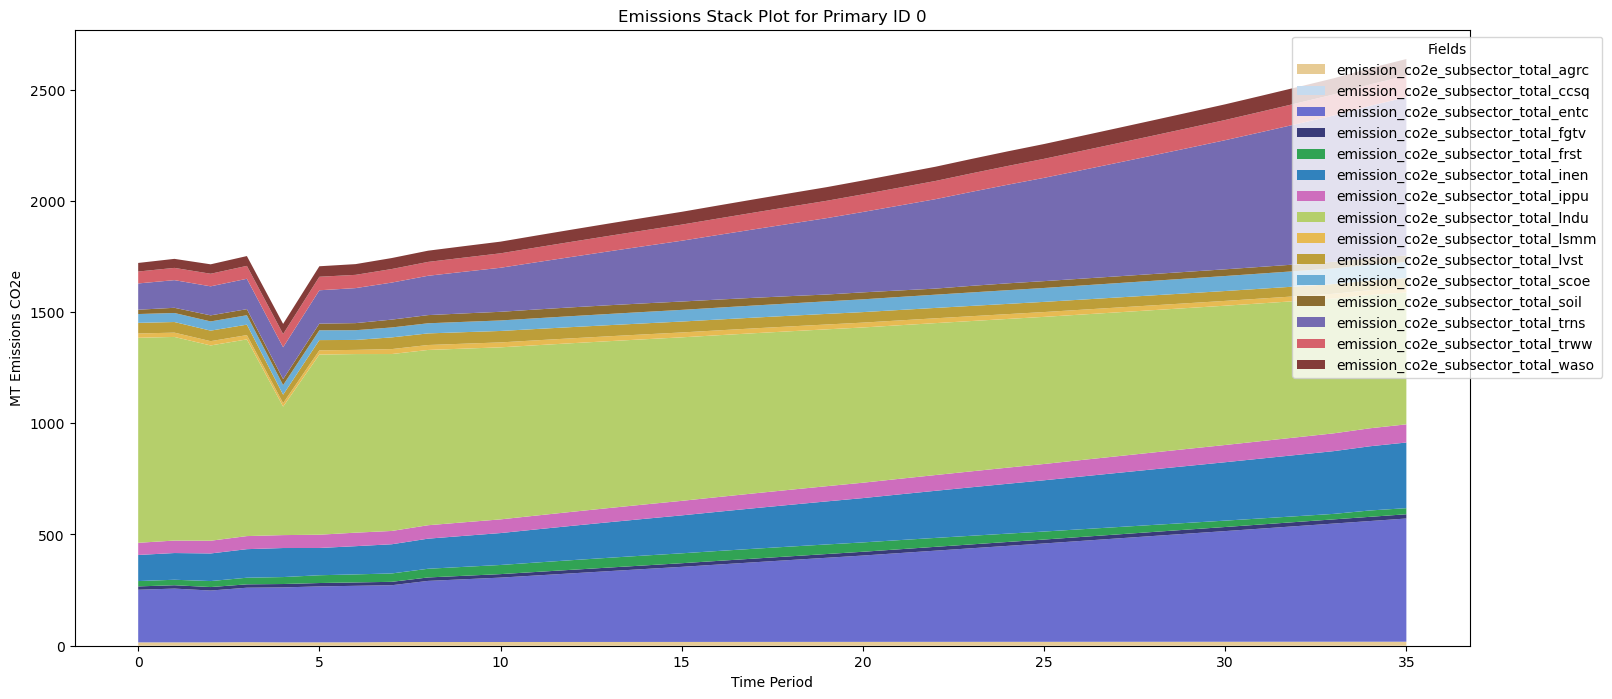

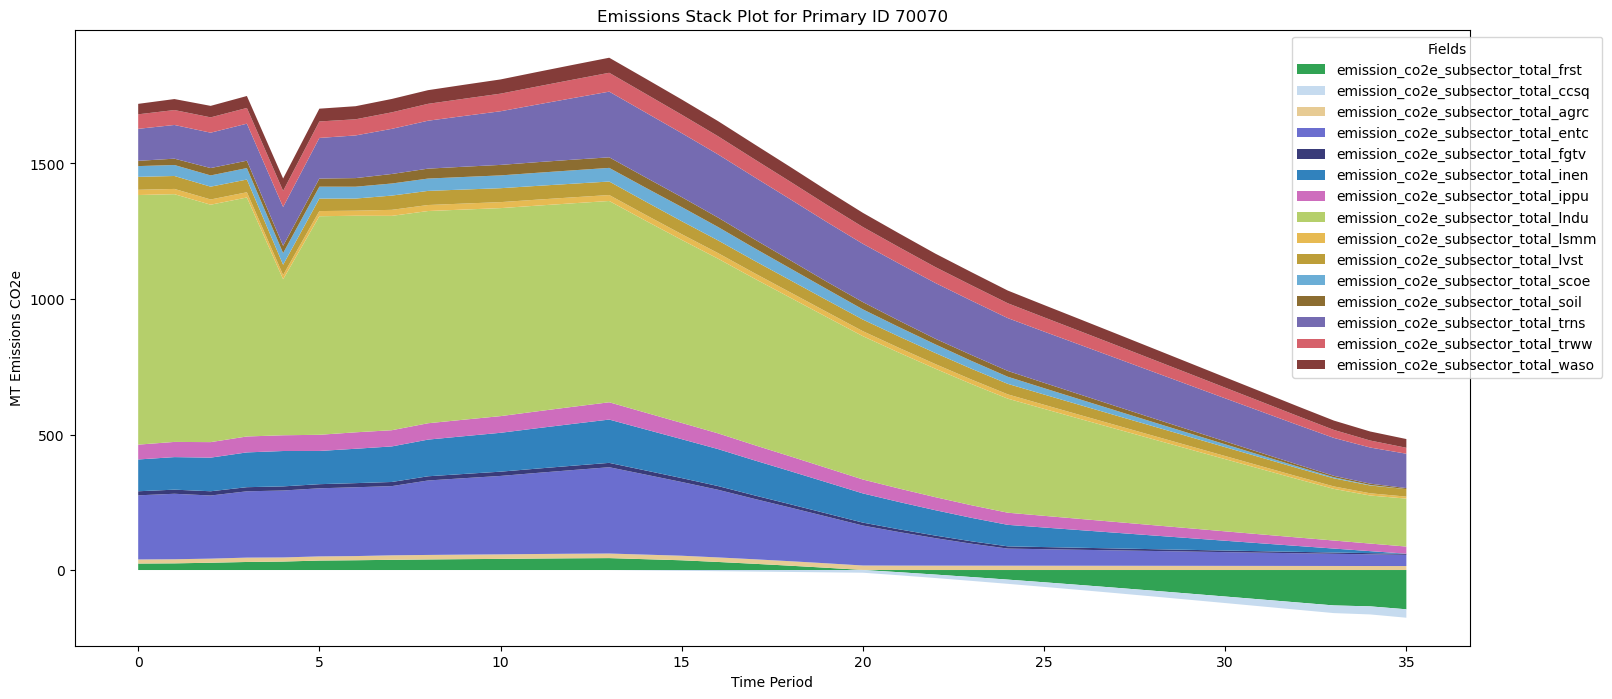

In [59]:
# Plot the emissions stack for the primary_id 0 (which is the baseline)
for primary_id in primary_ids_to_plot:

    plot_field_stack(
        df_out,
        subsector_emission_fields,
        dict_format,
        primary_id=primary_id,
        title=f"Emissions Stack Plot for Primary ID {primary_id}"
    )

# Export Wide File

In [60]:
all_primaries = sorted(list(df_out[ssp.key_primary].unique()))

# build if unable to simply read the data frame
if df_in is None:
    df_in = []
     
    for region in ssp.regions:
        for primary in all_primaries: 
            df_in_filt = ssp.generate_scenario_database_from_primary_key(primary)
            df_in.append(df_in_filt.get(region))
    
    df_in = pd.concat(df_in, axis = 0).reset_index(drop = True)




# sisepuede 2.0 echoes ~350 input vars in the output; merge on index keys only
# (merging on every shared column matches no rows and leaves all inputs NaN).
_keys = [ssp.key_primary, "region", "time_period"]
_cols_in = [c for c in df_in.columns if (c in _keys) or (c not in df_out.columns)]
df_export = pd.merge(
    df_out,
    df_in[_cols_in],
    how = "left",
    on = _keys,
)



# check output directory 
dir_pkg = os.path.join(
    ssp.file_struct.dir_out, 
    f"sisepuede_summary_results_run_{ssp.id_fs_safe}"
)
os.makedirs(dir_pkg) if not os.path.exists(dir_pkg) else None


for tab in ["ATTRIBUTE_STRATEGY"]:
    table_df = ssp.database.db.read_table(tab)
    if table_df is not None:
        table_df.to_csv(
            os.path.join(dir_pkg, f"{tab}.csv"),
            index=None,
            encoding="UTF-8"
        )
    else:
        print(f"Warning: Table {tab} returned None.")


df_primary = (
    ssp
    .odpt_primary
    .get_indexing_dataframe(
        sorted(list(df_out[ssp.key_primary].unique()))
    )
)
    
df_primary.to_csv(
    os.path.join(dir_pkg, f"ATTRIBUTE_PRIMARY.csv"),
    index = None,
    encoding = "UTF-8"
)

df_export.to_csv(
    os.path.join(dir_pkg, f"sisepuede_results_{ssp.id_fs_safe}_WIDE_INPUTS_OUTPUTS.csv"),
    index = None,
    encoding = "UTF-8"
)

In [61]:
# Getting the directory where the outputs are stored
dir_pkg

'/Users/fabianfuentes/miniconda3/envs/ssp_indonesia/lib/python3.13/site-packages/sisepuede/out/sisepuede_summary_results_run_sisepuede_run_2026-11-09T16;42;16.786760'

In [62]:
RUN_ID_OUTPUT_DIR_PATH = os.path.join(
    RUN_OUTPUT_DIR_PATH, 
    f"sisepuede_results_{ssp.id_fs_safe}"
)

os.makedirs(RUN_ID_OUTPUT_DIR_PATH, exist_ok=True)

df_primary.to_csv(
    os.path.join(RUN_ID_OUTPUT_DIR_PATH, "ATTRIBUTE_PRIMARY.csv"),
    index = None,
    encoding = "UTF-8"
)

df_export.to_csv(
    os.path.join(RUN_ID_OUTPUT_DIR_PATH, f"sisepuede_results_{ssp.id_fs_safe}_WIDE_INPUTS_OUTPUTS.csv"),
    index = None,
    encoding = "UTF-8"
)

for tab in ["ATTRIBUTE_STRATEGY"]:
    table_df = ssp.database.db.read_table(tab)
    if table_df is not None:
        table_df.to_csv(
            os.path.join(RUN_ID_OUTPUT_DIR_PATH, f"{tab}.csv"),
            index=None,
            encoding="UTF-8"
        )
    else:
        logger.warning(f"Warning: Table {tab} returned None.")

In [63]:
RUN_ID_OUTPUT_DIR_PATH

'/Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/ssp_run_output/sisepuede_results_sisepuede_run_2026-11-09T16;42;16.786760'

## Generate Levers Table

In [64]:
# strategies_to_run.remove(0)
# strategies_to_run

In [65]:
# import sisepuede.visualization.tables as svt
# tableau_levers_table = svt.LeversImplementationTable(strategies, )
# tableau_levers_table_csv = tableau_levers_table.build_table_for_strategies(
    # strategies_to_run
# )

# tableau_levers_table_csv.head()

In [66]:
# tableau_levers_table_csv.to_csv(
    # os.path.join(RUN_ID_OUTPUT_DIR_PATH, f"levers_implementation_{country_name}.csv"),
    # index=None,
    # encoding="UTF-8",
# )

## Post-processing pipeline — Tableau tables

Runs against the run we just produced. **No rescaling** (no intertemporal
decomposition): the tables are built directly from the raw
`*_WIDE_INPUTS_OUTPUTS.csv`.

Outputs land in `ssp_modeling/tableau/data/`:
- `emissions_indonesia.csv` — SISEPUEDE projection mapped to the IPCC crosswalk (projection only, no historical overlay).
- `drivers_indonesia.csv` — driver variables + GDP history.
- `tableau_levers_table_complete.csv` — levers merged with stakeholder codes.
- `jobs_demand_indonesia.csv` — employment subset (needs IDN rows in the employment file).


In [67]:
# 1. Post-processing config (Indonesia).
#    Rescaling / intertemporal decomposition is intentionally SKIPPED —
#    the Tableau tables below read the raw WIDE output directly.
REGION    = country_name                 # "indonesia"
ISO_CODE3 = config_params["country_code"]  # "IDN"
YEAR_REF  = 2019                          # BUR3 anchor year (first year shown in the tables)
RUN_DIR_PATH = pathlib.Path(RUN_ID_OUTPUT_DIR_PATH)

In [68]:
# 2. Tableau exports (emissions mapping + drivers + levers + jobs) — no rescaling
import importlib, shared_scripts.tableau_postprocessing
importlib.reload(shared_scripts.tableau_postprocessing)
from shared_scripts.tableau_postprocessing import run_tableau_postprocessing

tableau_outputs = run_tableau_postprocessing(
    run_dir     = RUN_DIR_PATH,
    project_dir = PROJECT_DIR_PATH,
    region      = REGION,       # "indonesia"
    iso_code3   = ISO_CODE3,    # "IDN"
    year_ref    = YEAR_REF,     # 2019
)

[emissions] /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/emissions_indonesia.csv  (3,672 rows)
[drivers]   /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/drivers_indonesia.csv  (268,920 rows)
[levers]    skipped — levers_implementation_indonesia.csv not found in /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/ssp_run_output/sisepuede_results_sisepuede_run_2026-11-09T16;42;16.786760
[jobs]      /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/jobs_demand_indonesia.csv  (0 rows)


## Cost-benefit analysis

Computes system + technical costs against the baseline using
`shared_scripts.cost_benefits_pipeline.run_cost_benefits`. **No rescaling**: it reads the
raw `WIDE_INPUTS_OUTPUTS.csv` directly (the removed intertemporal decomposition only
rescaled emissions; cost variables and GDP pass through unchanged, so cost-benefit
results are identical). Uses `ATTRIBUTE_PRIMARY` / `ATTRIBUTE_STRATEGY` from the run
directory and the Indonesia config `cb_config_params_indonesia.xlsx`. The requested
base `PFLO:BAU` falls back to `BASE` automatically when it was not run. Writes
Tableau-ready `cb_data.csv` to `ssp_modeling/tableau/data/`.

In [69]:
# 3. Cost-benefit analysis (delegates to shared_scripts/cost_benefits_pipeline.py)
#    No rescaling: feed the raw WIDE model output. The intertemporal decomposition
#    only rescaled emissions; cost variables and gdp_mmm_usd pass through unchanged,
#    so the cost-benefit results are identical.
from shared_scripts.data_loading import load_attribute_tables
from shared_scripts.cost_benefits_pipeline import run_cost_benefits

att_primary, att_strategy = load_attribute_tables(RUN_DIR_PATH)

wide_path = sorted(RUN_DIR_PATH.glob("*WIDE_INPUTS_OUTPUTS.csv"))[-1]
df_ssp = pd.read_csv(wide_path)
df_ssp = df_ssp[df_ssp["region"] == REGION].copy()

cb_data = run_cost_benefits(
    df_decomposed      = df_ssp,            # raw WIDE (no rescaling)
    att_primary        = att_primary,
    att_strategy       = att_strategy,
    cb_config_path     = SSP_MODELING_DIR_PATH / "cost-benefits" / "cb_config_files" / "cb_config_params_indonesia.xlsx",
    run_output_dir     = RUN_DIR_PATH,
    project_dir        = PROJECT_DIR_PATH,
    strategy_code_base = "PFLO:BAU",        # auto-falls back to BASE if not in this run
    output_path        = SSP_MODELING_DIR_PATH / "tableau" / "data" / "cb_data.csv",
)
print(f"cb_data: {cb_data.shape}")

[cb_pipeline] 'PFLO:BAU' not present in this run's strategies — falling back to 'BASE'.
Loading configuration from Excel file (fast path)
Database updated

************************************
*Strategy : PFLO:ALL (0/1)
************************************

---------Costs for: cb:agrc:crop_value:crops_produced:bevs_and_spices.
The variable is evaluated in System Cost
---------Costs for: cb:agrc:crop_value:crops_produced:cereals.
The variable is evaluated in System Cost
---------Costs for: cb:agrc:crop_value:crops_produced:fibers.
The variable is evaluated in System Cost
---------Costs for: cb:agrc:crop_value:crops_produced:fruits.
The variable is evaluated in System Cost
---------Costs for: cb:agrc:crop_value:crops_produced:herbs.
The variable is evaluated in System Cost
---------Costs for: cb:agrc:crop_value:crops_produced:nuts.
The variable is evaluated in System Cost
---------Costs for: cb:agrc:crop_value:crops_produced:other_annual.
The variable is evaluated in System Cost
--------

## 5. Tableau handoff — file paths

All postprocessing outputs are now available in `ssp_modeling/tableau/data/`. Load these CSVs into the Tableau workbook.

In [70]:
# Tableau handoff — list all output files with absolute paths + row counts + sizes
import pandas as pd

TABLEAU_OUT_DIR = SSP_MODELING_DIR_PATH / "tableau" / "data"
print(f"\n{'='*80}")
print(f"  TABLEAU-READY FILES at {TABLEAU_OUT_DIR}")
print(f"{'='*80}\n")

# All CSVs in tableau/data/
output_files = sorted(TABLEAU_OUT_DIR.glob("*.csv"))
for f in output_files:
    try:
        n_rows = sum(1 for _ in open(f)) - 1
    except Exception:
        n_rows = "?"
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name}")
    print(f"      path:  {f}")
    print(f"      rows:  {n_rows:,}" if isinstance(n_rows, int) else f"      rows:  {n_rows}")
    print(f"      size:  {size_kb:,.1f} KB\n")

print(f"\n{'='*80}")
print("  RECOMMENDED TABLEAU DASHBOARD STRUCTURE")
print(f"{'='*80}")
print("""
  1. Executive Summary       — Net-Zero trajectory by sector (area chart)
  2. Targets vs Achievement  — Sortable matrix with PASS/WARN/FAIL status icons
  3. Energy & Power          — Generation mix, efficiency, emissions
  4. Transport               — Modal split, EV stock, demand
  5. Industry (IPPU + INEN)  — Production volumes, HFCs, CCS
  6. AFOLU                   — Sector emissions, forest sink gap visible
  7. Waste                   — Recycling, methane capture
  8. Levers & Strategy Comparison — Ramp profiles per strategy
  9. Methodology & Caveats   — LSMM paradox, cement artifact, gaps
""")

print(f"\n{'='*80}")
print("  PIPELINE COMPLETE — ready to open Tableau workbook")
print(f"{'='*80}\n")


  TABLEAU-READY FILES at /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data

  cb_data.csv
      path:  /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/cb_data.csv
      rows:  11,276
      size:  3,195.0 KB

  drivers_indonesia.csv
      path:  /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/drivers_indonesia.csv
      rows:  268,920
      size:  62,070.1 KB

  emissions_indonesia.csv
      path:  /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/emissions_indonesia.csv
      rows:  3,672
      size:  761.6 KB

  jobs_demand_indonesia.csv
      path:  /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/jobs_demand_indonesia.csv
      rows:  0
      size:  0.1 KB

  tableau_levers_table_complete.csv
      path:  /Users/fabianfuentes/git/ssp_indonesia/ssp_modeling/tableau/data/tableau_levers_table_complete.csv
      rows:  2,592
      size:  741.8 KB


  RECOMMENDED TABLEAU DASHBOARD STRUCTURE

  1. Executive S